In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

import specula
specula.init(-1)    # CPU: the notebook only builds data objects, simulations run in a separate process
from specula.mmlib.yaml_overrides import write_yaml_overrides
from save_kalman_data import save_kalman_data
from utils import (calib_dir, result_dir, run_specula, latest_tn, get_noise_propagation, paths, get_rec,
                   get_aliasing_power, get_atmo_coeffs, get_static_slopes, get_static_modes, get_pupil_flux)

2026-11-06 17:42:21,699 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-06 17:42:21,700 [INFO]: [specula]: Default device is CPU


In [2]:
# calib_dir, result_dir: imported from utils
overrides_yaml = 'temp_overrides'

In [3]:
# Filter / simulation parameters: everything below (slope nulls, Kalman data, simulation overrides) is derived from these
dt = 0.0005              # [s] loop time step (main.time_step)
tau = 250e-6 / dt        # fractional delay (kpred.delay) [steps]; the Kalman filter predicts 1 + tau steps ahead
n_subaps, n_modes = 48, 1300
sigma_e = 0.5            # [e-] RON (cred_*.readout_level)
# Guide-star magnitudes of the run (source_vis / source_nir), and those of the calibration frames (ristretto_main.yml)
mag_vis, mag_nir = 7.00, 6.43
mag_vis_cal, mag_nir_cal = 7.00, 6.43
vis = dict(rMod=3.0, wvl=900,  mag=mag_vis, mag_cal=mag_vis_cal, frame_steps=4, biased=False)   # pyr_vis: reference sensor
nir = dict(rMod=1.0, wvl=1300, mag=mag_nir, mag_cal=mag_nir_cal, frame_steps=1, biased=True)    # pyr_nir: offset estimated
# Total pupil flux per frame of each sensor [e-], as PyrSlopec 'out_flux' reports it: taken from the saved calibration
# frames (they include QE, telescope pupil and the light falling outside the four pupils), scaled to frame time and magnitude
for s in (vis, nir):
    s['flux'] = get_pupil_flux(s['rMod'], n_subaps, n_modes, s['wvl']) * s['frame_steps'] * 10**(-0.4 * (s['mag'] - s['mag_cal']))
    print(f"{s['wvl']} nm: {s['flux']:.3g} e- per frame")

kf_tag = f"kf_ar2_{n_modes}modes_vis{vis['rMod']:1.1f}_nir{nir['rMod']:1.1f}"   # kalman.kalman_filter_data_object
iir_tag = f'unity_{n_modes}modes'                                                  # kpred.iir_filter_data_object
# bias_tag = f"nir_bias_{n_modes}modes_vis{vis['rMod']:1.1f}_nir{nir['rMod']:1.1f}"
# pyr_modes_*.recmat_object (aoeb names); get_rec makes the reconstructor of a wavelength that was not calibrated (scaled IM)
for s in (vis, nir):
    get_rec(s['rMod'], n_subaps, n_modes, s['wvl'])
rec_vis_tag = os.path.basename(paths(vis['wvl']).rec(vis['rMod'], n_subaps, n_modes))[:-5]
rec_nir_tag = os.path.basename(paths(nir['wvl']).rec(nir['rMod'], n_subaps, n_modes))[:-5]

900 nm: 4.13e+05 e- per frame
1300 nm: 9.01e+04 e- per frame


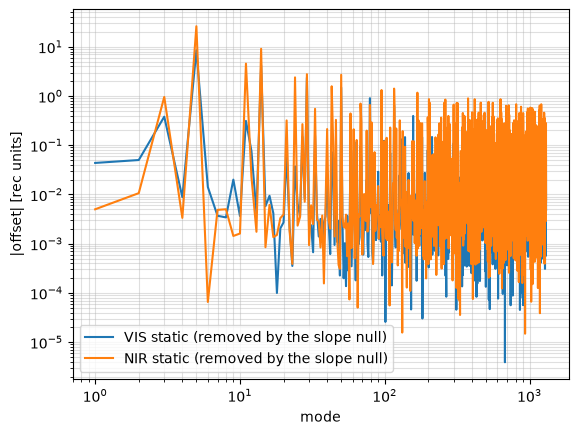

In [4]:
from specula.data_objects.slopes import Slopes
# Slope nulls of both sensors: slopes of the mean residual frame saved by the aliasing calibration (main_simul).
# pyr_slopes_*.sn_object subtracts them, so both sensors read zero on that residual.
slopes_vis = get_static_slopes(vis['rMod'], n_subaps, n_modes, vis['wvl'])
slopes_nir = get_static_slopes(nir['rMod'], n_subaps, n_modes, nir['wvl'])
slopesn = Slopes(slopes=slopes_nir)
slopesv = Slopes(slopes=slopes_vis)
slopes_nir_tag = f"pyr{nir['rMod']:1.1f}_{n_subaps}x{n_subaps}_nir_sn"
slopes_vis_tag = f"pyr{vis['rMod']:1.1f}_{n_subaps}x{n_subaps}_vis_sn"
os.makedirs(os.path.join(calib_dir, 'slopenulls'), exist_ok=True)
slopesn_file = os.path.join(calib_dir, 'slopenulls', slopes_nir_tag + '.fits')
slopesv_file = os.path.join(calib_dir, 'slopenulls', slopes_vis_tag + '.fits')
slopesv.save(slopesv_file)
slopesn.save(slopesn_file)

# What the nulls remove, in reconstructor units
static_vis = get_static_modes(vis['rMod'], n_subaps, n_modes, vis['wvl'])
static_nir = get_static_modes(nir['rMod'], n_subaps, n_modes, nir['wvl'])

# Initial bias of the NIR offset estimation. With the slope nulls on it must be zero: static_nir - static_vis counts the offsets twice
# nir_bias = static_nir - static_vis
# os.makedirs(os.path.join(calib_dir, 'data'), exist_ok=True)
# bias_file = os.path.join(calib_dir, 'data', bias_tag + '.fits')
# fits.writeto(bias_file, nir_bias, overwrite=True)
# print('saved', bias_file)

x = np.arange(n_modes) + 1
plt.figure()
plt.loglog(x, np.abs(static_vis), label='VIS static (removed by the slope null)')
plt.loglog(x, np.abs(static_nir), label='NIR static (removed by the slope null)')
# plt.loglog(x, np.abs(nir_bias), label='NIR bias (NIR - VIS)')
plt.xlabel('mode'); plt.ylabel('|offset| [rec units]')
plt.legend(); plt.grid(which='both', alpha=0.4)

In [5]:
# Kalman filter data (kalman.kalman_filter_data_object) and identity IIR of the delay (kpred.iir_filter_data_object)
a1, a2, q = get_atmo_coeffs(dt)    # AR(2) at the loop rate

sensors = []
for s in (vis, nir):    # same order as kalman.inputs.in_measurements_list
    args = (s['rMod'], n_subaps, n_modes, s['wvl'])
    sensors.append(dict(
        noise_var=get_noise_propagation(*args, sigma_e, s['flux'], pupil_flux=True) ** 2,   # fixed: rebuild if the flux changes
        aliasing=get_aliasing_power(*args, fs=1 / (s['frame_steps'] * dt)),                 # white, variance per frame of the sensor
        frame_steps=s['frame_steps'], 
        # biased=s['biased']))
        biased=False))
# Bias estimation: biased=s['biased'] above, these two lines, and out_bias + kf_bias in ristretto_main.yml
# sensors[1]['bias'] = fits.getdata(bias_file)        # initial NIR offset (cell above)
# sensors[1]['bias_var'] = 0.1 ** 2                   # prior variance of the NIR offset around zero (slope nulls) [rec units^2]

fn = save_kalman_data(kf_tag, calib_dir, a1, a2, q, sensors, n_modes=n_modes, plant_inverse_tag=iir_tag, beta=0.0, delay=1 + tau)
print('saved', fn)

saved /raid1/mmenessini/calibration/WFSW/filter/kf_ar2_1300modes_vis3.0_nir1.0.fits


In [6]:
# Closed-loop simulation with the filter built above (ristretto_main.yml + overrides). Log: specula.log
total_time = 1.0         # [s]
ovdes = ("{"
    f"main.time_step: {dt}, "
    f"main.total_time: {total_time}, "
    f"main.root_dir: '{calib_dir}', "
    f"pyr_vis.pup_diam: {n_subaps}, "
    f"pyr_vis.mod_amp: {vis['rMod']:1.1f}, "
    f"pyr_vis.wavelengthInNm: {vis['wvl']}, "
    f"source_vis.wavelengthInNm: {vis['wvl']}, "
    f"source_vis.magnitude: {vis['mag']}, "
    f"cred_vis.dt: {vis['frame_steps'] * dt}, "
    f"cred_vis.readout_level: {sigma_e}, "
    f"pyr_slopes_vis.pupdata_object: 'pyr_pupdata_{n_subaps}x{n_subaps}', "
    f"pyr_slopes_vis.sn_object: '{slopes_vis_tag}', "
    f"pyr_modes_vis.recmat_object: '{rec_vis_tag}', "
    f"pyr_nir.pup_diam: {n_subaps}, "
    f"pyr_nir.mod_amp: {nir['rMod']:1.1f}, "
    f"pyr_nir.wavelengthInNm: {nir['wvl']}, "
    f"source_nir.wavelengthInNm: {nir['wvl']}, "
    f"source_nir.magnitude: {nir['mag']}, "
    f"cred_nir.dt: {nir['frame_steps'] * dt}, "
    f"cred_nir.readout_level: {sigma_e}, "
    f"pyr_slopes_nir.pupdata_object: 'pyr_pupdata_{n_subaps}x{n_subaps}', "
    f"pyr_slopes_nir.sn_object: '{slopes_nir_tag}', "
    f"pyr_modes_nir.recmat_object: '{rec_nir_tag}', "
    f"kalman.kalman_filter_data_object: '{kf_tag}', "
    f"kalman.time_step: {dt}, "
    f"kpred.iir_filter_data_object: '{iir_tag}', "
    f"kpred.delay: {tau}, "
    "}")
write_yaml_overrides(ovdes, temp_name=overrides_yaml)
run_specula('ristretto_main.yml', overrides_yaml, log_file='specula.log')
tn = latest_tn()
print('done:', os.path.join(result_dir, tn))

done: /raid1/mmenessini/results/WFSW/20261106_174228


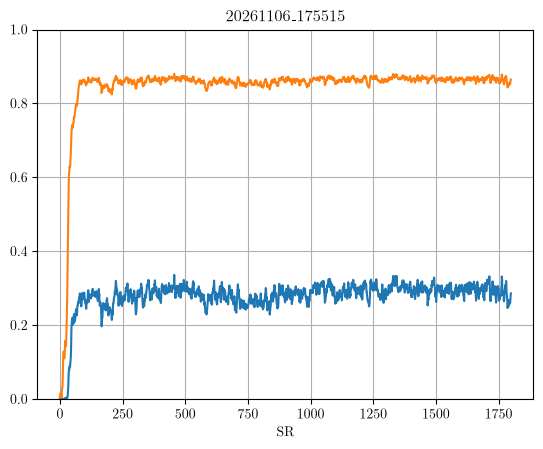

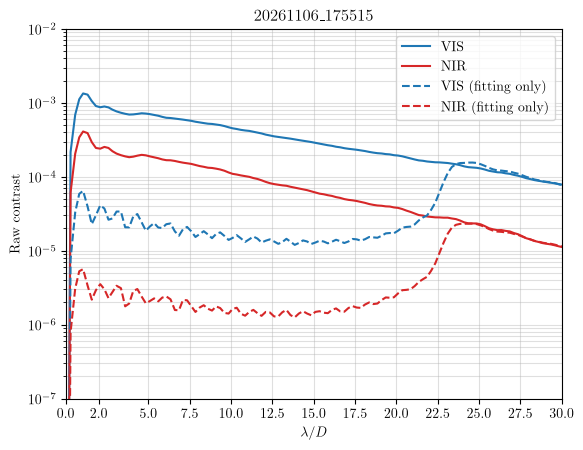

In [5]:
from results_analysis import (load_coro_profile, modal_plot, plot_coro_profiles, plot_sr, get_results_path)

tn = 'sweep_contrast_rmod0_20261106/runs/20261106_175515'
tn_path = get_results_path(tn)

# # Mean raw contrast in 2-5 lambda/D and mean SR, after coro_psf_*.start_time (the metric of sweep_contrast.py)
# start_time = 0.5         # [s]
# print(tn)
# for band, wvl in (('vis', 550), ('nir', 1650)):
#     rad, prof = load_coro_profile(tn_path, band)
#     sr = fits.getdata(os.path.join(tn_path, f'sr_{band}.fits'))
#     print(f"{wvl} nm: contrast 2-5 lambda/D = {np.mean(prof[(rad >= 2) & (rad <= 5)]):.3e}, SR = {np.mean(sr[int(round(start_time / dt)):]):.4f}")

plot_sr(tn_path)
# modal_plot(tn_path)
plot_coro_profiles(tn_path)

# # Quick look at the run
# kf_bias = fits.getdata(os.path.join(result_dir, tn, 'kf_bias.fits'))
# plt.figure()
# plt.loglog(x, np.abs(nir_bias), label='initial bias')
# plt.loglog(x, np.abs(kf_bias[-1][:n_modes]), label='estimated bias (end of run)')
# plt.xlabel('mode'); plt.legend(); plt.grid(which='both', alpha=0.4)